# Day 041 | Decision Trees
## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** 2026-05-16  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Decision tree | Flowchart of if/else rules | If N>30 and depth_to_rock<3m then shallow foundation |
| Gini impurity | Measure of class mixing at a node | How pure is a node (all deep foundations or mixed?) |
| Information gain | Reduction in impurity from a split | Which feature best separates foundation types? |
| Tree visualization | See the learned rules | Export the tree as a readable diagram |
| Max depth | Limit tree growth to prevent overfitting | Shallow tree = simpler rules |
| Feature importance | Which features drive decisions | Is N-value or building stories more important? |

---

## Our Geotechnical Problem

A structural engineer needs to recommend a **foundation type** (Shallow, Deep, or Pile) for a set of building projects. The decision depends on:

- **Soil type** at the site
- **N-value** from SPT testing
- **Number of building stories**
- **Applied load** (kN)
- **Water table depth** (m)
- **Depth to rock** (m)

Decision trees learn these rules automatically from historical data, creating an interpretable flowchart that engineers can follow. Unlike KNN, decision trees produce **rules** that can be explained to clients and regulators.

---

## Part 1: Generate Foundation Design Data

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder

np.random.seed(42)
print("All imports successful.")

All imports successful.


In [2]:
# ─────────────────────────────────────────────────────
# GENERATE FOUNDATION DESIGN DATA
# ─────────────────────────────────────────────────────

n_samples = 100
soil_types = np.random.choice(['Clay', 'Sand', 'Silt', 'Gravel'], n_samples, p=[0.3, 0.3, 0.25, 0.15])
N_value = np.random.randint(3, 55, n_samples)
building_stories = np.random.randint(1, 25, n_samples)
load_kN = np.round(building_stories * np.random.uniform(150, 400, n_samples), 0).astype(int)
water_table = np.round(np.random.uniform(0.5, 15.0, n_samples), 1)
depth_to_rock = np.round(np.random.uniform(1.0, 30.0, n_samples), 1)

# Rule-based foundation recommendation (realistic engineering logic)
foundation = []
for i in range(n_samples):
    if building_stories[i] <= 3 and N_value[i] >= 15 and depth_to_rock[i] <= 5:
        foundation.append('Shallow')
    elif building_stories[i] >= 10 or load_kN[i] >= 3000:
        if soil_types[i] in ['Clay', 'Silt'] or N_value[i] < 15:
            foundation.append('Pile')
        else:
            foundation.append('Deep')
    elif N_value[i] < 10 or water_table[i] < 2.0:
        foundation.append('Pile')
    elif building_stories[i] <= 5 and N_value[i] >= 20:
        foundation.append('Shallow')
    else:
        foundation.append('Deep')

df = pd.DataFrame({
    'soil_type': soil_types,
    'N_value': N_value,
    'building_stories': building_stories,
    'load_kN': load_kN,
    'water_table': water_table,
    'depth_to_rock': depth_to_rock,
    'recommended_foundation': foundation
})

df.to_csv('foundation_design.csv', index=False)
print(f"Dataset shape: {df.shape}")
print(f"\nFoundation type distribution:\n{df['recommended_foundation'].value_counts()}")
print(f"\nFirst 5 rows:")
df.head()

Dataset shape: (100, 7)

Foundation type distribution:
recommended_foundation
Pile       56
Deep       23
Shallow    21
Name: count, dtype: int64

First 5 rows:


,soil_type,N_value,building_stories,load_kN,water_table,depth_to_rock,recommended_foundation
0,Sand,34,9,1789,1.2,3.4,Pile
1,Gravel,41,6,1984,1.1,21.3,Pile
2,Silt,51,16,3523,12.9,3.1,Pile
3,Sand,54,3,468,10.7,24.8,Shallow
4,Clay,34,20,6227,7.4,21.5,Pile


In [3]:
# ─────────────────────────────────────────────────────
# EXPLORE THE DATA
# ─────────────────────────────────────────────────────

print("Summary statistics by foundation type:")
print("=" * 70)
for ftype in ['Shallow', 'Deep', 'Pile']:
    subset = df[df['recommended_foundation'] == ftype]
    print(f"\n{ftype} Foundation (n={len(subset)}):")
    print(f"  N-value:         {subset['N_value'].mean():5.1f} (range: {subset['N_value'].min()}-{subset['N_value'].max()})")
    print(f"  Building stories:{subset['building_stories'].mean():5.1f} (range: {subset['building_stories'].min()}-{subset['building_stories'].max()})")
    print(f"  Load (kN):       {subset['load_kN'].mean():7.0f} (range: {subset['load_kN'].min()}-{subset['load_kN'].max()})")
    print(f"  Water table (m): {subset['water_table'].mean():5.1f}")
    print(f"  Depth to rock:   {subset['depth_to_rock'].mean():5.1f}")

Summary statistics by foundation type:

Shallow Foundation (n=21):
  N-value:          41.0 (range: 21-54)
  Building stories:  2.6 (range: 1-5)
  Load (kN):           744 (range: 179-1628)
  Water table (m):   8.2
  Depth to rock:    16.7

Deep Foundation (n=23):
  N-value:          32.9 (range: 15-51)
  Building stories: 12.8 (range: 1-24)
  Load (kN):          3502 (range: 309-7950)
  Water table (m):   9.0
  Depth to rock:    18.6

Pile Foundation (n=56):
  N-value:          24.4 (range: 3-54)
  Building stories: 15.1 (range: 1-24)
  Load (kN):          4185 (range: 392-8940)
  Water table (m):   7.0
  Depth to rock:    16.6


---

## Part 2: How Decision Trees Work

A decision tree splits data using if/else rules:

1. **Start** with all samples at the root node
2. **Find** the feature and threshold that best separates the classes
3. **Split** into left (condition true) and right (condition false) children
4. **Repeat** recursively until stopping criteria are met

**Gini Impurity** measures how "mixed" a node is:
$$Gini = 1 - \sum_{i=1}^{C} p_i^2$$

- Gini = 0: Pure node (all same class)
- Gini = 0.5: Maximum impurity for 2 classes (50/50 mix)

**Information Gain** = parent impurity minus weighted average of children impurity. The split with the highest information gain is chosen.

In [4]:
# ─────────────────────────────────────────────────────
# GINI IMPURITY DEMONSTRATION
# ─────────────────────────────────────────────────────

def gini_impurity(labels):
    """Calculate Gini impurity for a set of labels."""
    n = len(labels)
    if n == 0:
        return 0
    _, counts = np.unique(labels, return_counts=True)
    probs = counts / n
    return 1 - np.sum(probs ** 2)

# Example nodes
pure_node = ['Shallow'] * 20
mixed_node = ['Shallow'] * 10 + ['Deep'] * 10
three_class = ['Shallow'] * 10 + ['Deep'] * 5 + ['Pile'] * 5

print("Gini Impurity Examples")
print("=" * 50)
print(f"Pure node (all Shallow):      Gini = {gini_impurity(pure_node):.4f}")
print(f"50/50 mix (Shallow/Deep):     Gini = {gini_impurity(mixed_node):.4f}")
print(f"Three-class mix (10/5/5):     Gini = {gini_impurity(three_class):.4f}")
print(f"\nGini = 0 means perfectly pure (ideal).")
print(f"Higher Gini = more mixed classes (we want to reduce this).")

Gini Impurity Examples
Pure node (all Shallow):      Gini = 0.0000
50/50 mix (Shallow/Deep):     Gini = 0.5000
Three-class mix (10/5/5):     Gini = 0.6250

Gini = 0 means perfectly pure (ideal).
Higher Gini = more mixed classes (we want to reduce this).


---

## Part 3: Prepare Data and Train Decision Tree

In [5]:
# ─────────────────────────────────────────────────────
# ENCODE CATEGORICAL FEATURES AND SPLIT
# ─────────────────────────────────────────────────────

# Encode soil_type as integers
le_soil = LabelEncoder()
df['soil_type_encoded'] = le_soil.fit_transform(df['soil_type'])

feature_cols = ['soil_type_encoded', 'N_value', 'building_stories', 'load_kN', 'water_table', 'depth_to_rock']
feature_names = ['soil_type', 'N_value', 'building_stories', 'load_kN', 'water_table', 'depth_to_rock']
X = df[feature_cols]
y = df['recommended_foundation']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training: {X_train.shape[0]} samples")
print(f"Testing:  {X_test.shape[0]} samples")
print(f"\nSoil type encoding: {dict(zip(le_soil.classes_, le_soil.transform(le_soil.classes_)))}")
print(f"\nClass distribution (train):\n{y_train.value_counts()}")

Training: 80 samples
Testing:  20 samples

Soil type encoding: {'Clay': np.int64(0), 'Gravel': np.int64(1), 'Sand': np.int64(2), 'Silt': np.int64(3)}

Class distribution (train):
recommended_foundation
Pile       45
Deep       18
Shallow    17
Name: count, dtype: int64


In [6]:
# ─────────────────────────────────────────────────────
# TRAIN DECISION TREE (no depth limit)
# ─────────────────────────────────────────────────────

dt_full = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_full.fit(X_train, y_train)

train_acc = dt_full.score(X_train, y_train)
test_acc = dt_full.score(X_test, y_test)

print(f"Decision Tree (unlimited depth)")
print(f"  Tree depth:     {dt_full.get_depth()}")
print(f"  Number of leaves: {dt_full.get_n_leaves()}")
print(f"  Training accuracy: {train_acc:.2%}")
print(f"  Test accuracy:     {test_acc:.2%}")
print(f"\n{'Overfitting!' if train_acc - test_acc > 0.1 else 'Looks reasonable.'}")

Decision Tree (unlimited depth)
  Tree depth:     7
  Number of leaves: 14
  Training accuracy: 100.00%
  Test accuracy:     80.00%

Overfitting!


---

## Part 4: Visualize the Decision Tree

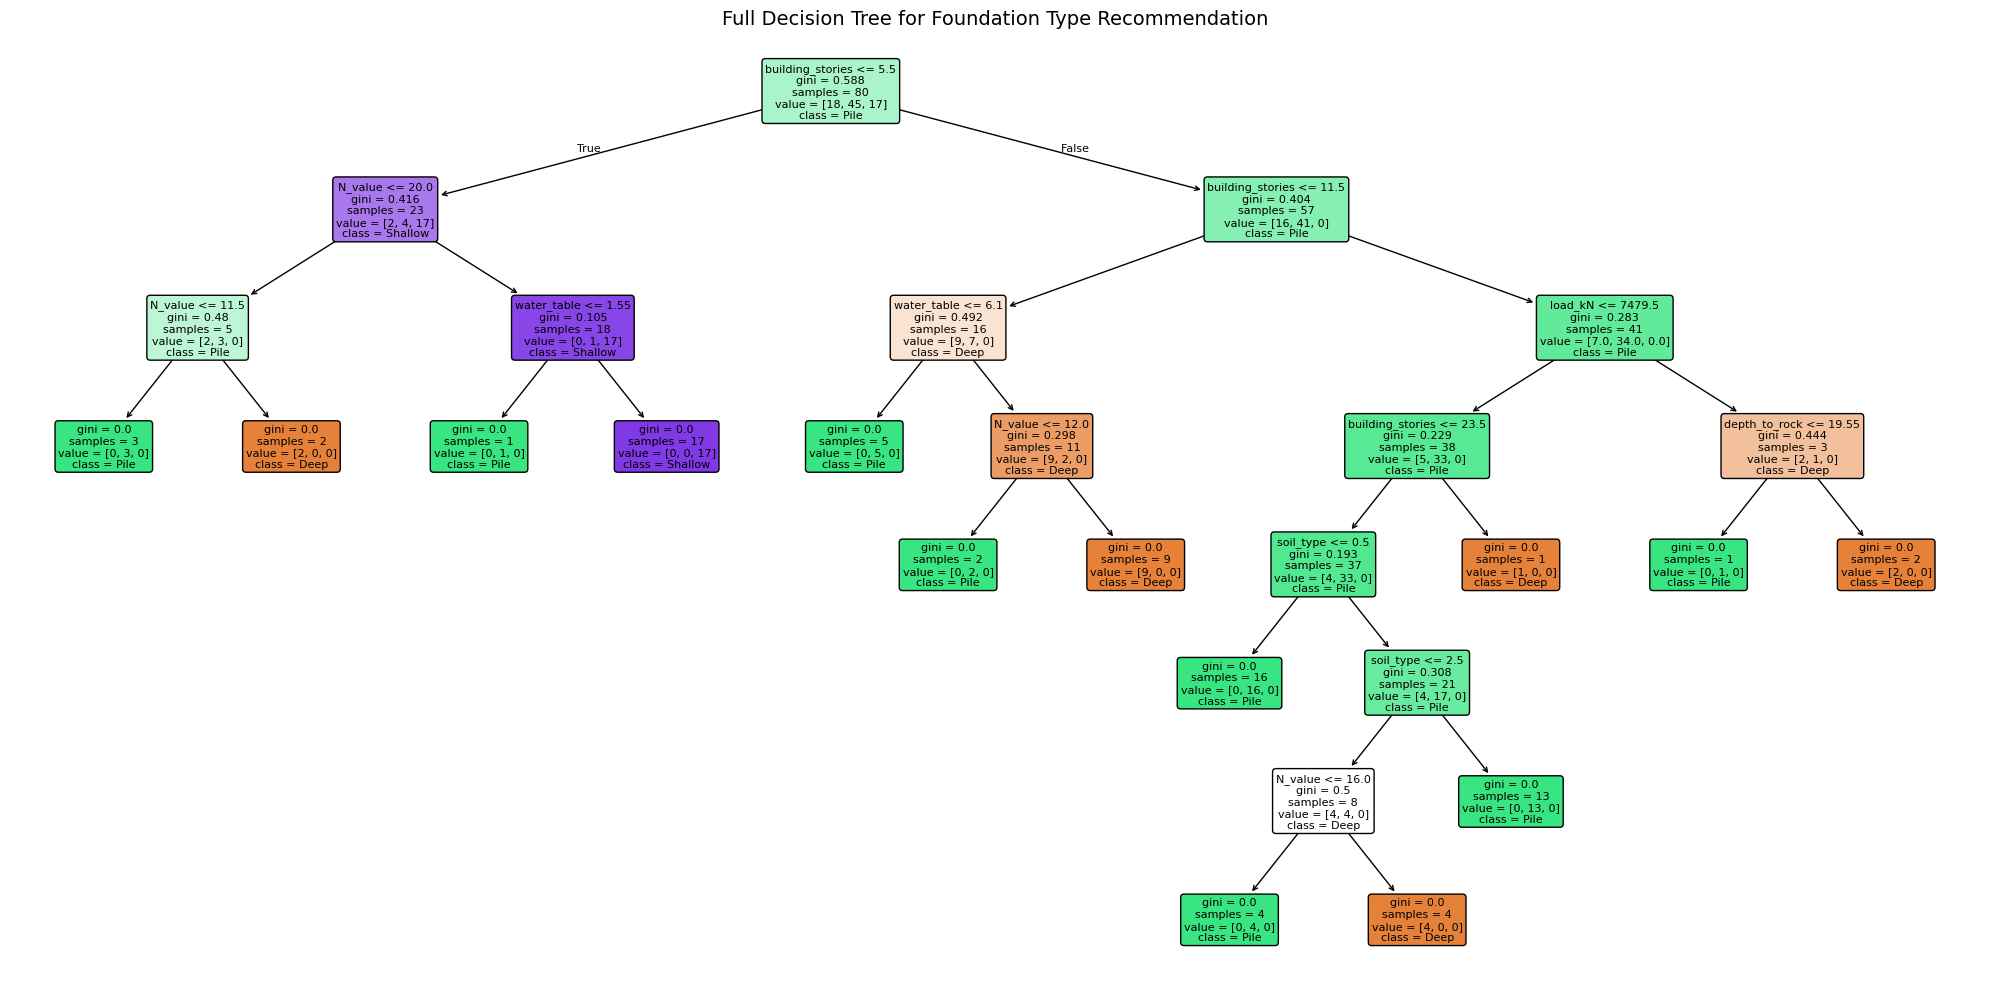

Each node shows: feature <= threshold, gini, samples, class.
Color intensity = confidence (darker = more pure).


In [7]:
# ─────────────────────────────────────────────────────
# VISUALIZE FULL TREE
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(dt_full,
          feature_names=feature_names,
          class_names=dt_full.classes_,
          filled=True,
          rounded=True,
          fontsize=8,
          ax=ax)
ax.set_title('Full Decision Tree for Foundation Type Recommendation', fontsize=14)
plt.tight_layout()
plt.show()

print("Each node shows: feature <= threshold, gini, samples, class.")
print("Color intensity = confidence (darker = more pure).")

In [8]:
# ─────────────────────────────────────────────────────
# TEXT REPRESENTATION OF THE TREE
# ─────────────────────────────────────────────────────

tree_text = export_text(dt_full, feature_names=feature_names, max_depth=4)
print("Decision Tree Rules (first 4 levels):")
print("=" * 60)
print(tree_text)
print("\nThese rules can be read like an engineering specification:")
print("  If building_stories <= 9.5 AND N_value > 9.5 ... => Shallow")

Decision Tree Rules (first 4 levels):
|--- building_stories <= 5.50
|   |--- N_value <= 20.00
|   |   |--- N_value <= 11.50
|   |   |   |--- class: Pile
|   |   |--- N_value >  11.50
|   |   |   |--- class: Deep
|   |--- N_value >  20.00
|   |   |--- water_table <= 1.55
|   |   |   |--- class: Pile
|   |   |--- water_table >  1.55
|   |   |   |--- class: Shallow
|--- building_stories >  5.50
|   |--- building_stories <= 11.50
|   |   |--- water_table <= 6.10
|   |   |   |--- class: Pile
|   |   |--- water_table >  6.10
|   |   |   |--- N_value <= 12.00
|   |   |   |   |--- class: Pile
|   |   |   |--- N_value >  12.00
|   |   |   |   |--- class: Deep
|   |--- building_stories >  11.50
|   |   |--- load_kN <= 7479.50
|   |   |   |--- building_stories <= 23.50
|   |   |   |   |--- soil_type <= 0.50
|   |   |   |   |   |--- class: Pile
|   |   |   |   |--- soil_type >  0.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- building_stories >  23.50
|   |   |   |   |---

---

## Part 5: Controlling Overfitting with max_depth

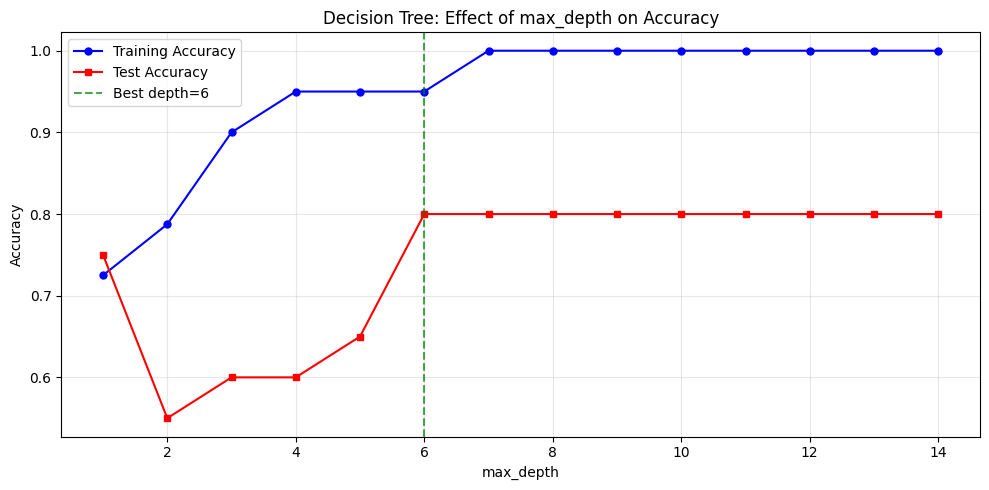

Best max_depth = 6, test accuracy = 80.00%
Unlimited depth: train=100.00%, test=80.00%

Shallower trees generalize better — they capture the main rules
without memorizing noise in the training data.


In [9]:
# ─────────────────────────────────────────────────────
# EFFECT OF MAX DEPTH
# ─────────────────────────────────────────────────────

depths = range(1, 15)
train_accs = []
test_accs = []

for d in depths:
    dt_d = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt_d.fit(X_train, y_train)
    train_accs.append(dt_d.score(X_train, y_train))
    test_accs.append(dt_d.score(X_test, y_test))

best_depth = list(depths)[np.argmax(test_accs)]
best_test_acc = max(test_accs)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_accs, 'b-o', markersize=5, label='Training Accuracy')
ax.plot(depths, test_accs, 'r-s', markersize=5, label='Test Accuracy')
ax.axvline(x=best_depth, color='green', linestyle='--', alpha=0.7, label=f'Best depth={best_depth}')
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy')
ax.set_title('Decision Tree: Effect of max_depth on Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best max_depth = {best_depth}, test accuracy = {best_test_acc:.2%}")
print(f"Unlimited depth: train={train_acc:.2%}, test={test_acc:.2%}")
print(f"\nShallower trees generalize better — they capture the main rules")
print(f"without memorizing noise in the training data.")

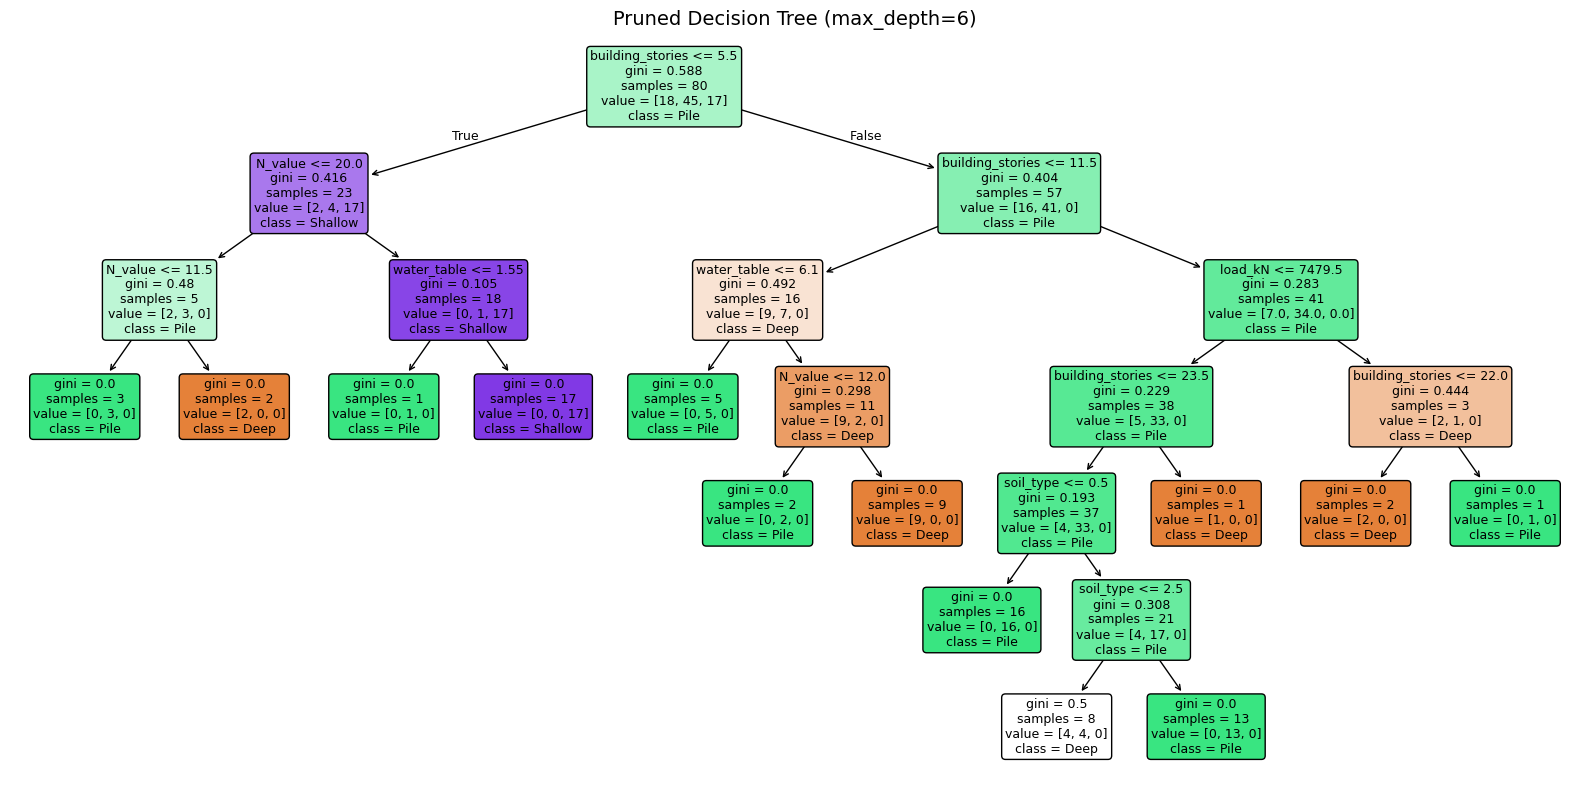


Pruned tree accuracy: 80.00%
Number of leaves: 13 (vs 14 in full tree)


In [10]:
# ─────────────────────────────────────────────────────
# PRUNED TREE — Simpler and more interpretable
# ─────────────────────────────────────────────────────

dt_pruned = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_pruned.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(dt_pruned,
          feature_names=feature_names,
          class_names=dt_pruned.classes_,
          filled=True,
          rounded=True,
          fontsize=9,
          ax=ax)
ax.set_title(f'Pruned Decision Tree (max_depth={best_depth})', fontsize=14)
plt.tight_layout()
plt.show()

y_pred = dt_pruned.predict(X_test)
print(f"\nPruned tree accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Number of leaves: {dt_pruned.get_n_leaves()} (vs {dt_full.get_n_leaves()} in full tree)")

---

## Part 6: Gini vs Entropy (Information Gain)

In [11]:
# ─────────────────────────────────────────────────────
# COMPARE GINI vs ENTROPY
# ─────────────────────────────────────────────────────

dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=best_depth, random_state=42)
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=best_depth, random_state=42)

dt_gini.fit(X_train, y_train)
dt_entropy.fit(X_train, y_train)

acc_gini = dt_gini.score(X_test, y_test)
acc_entropy = dt_entropy.score(X_test, y_test)

print("Splitting Criteria Comparison")
print("=" * 40)
print(f"Gini impurity:    {acc_gini:.2%}")
print(f"Entropy (info gain): {acc_entropy:.2%}")
print(f"\nIn practice, Gini and entropy usually give very similar results.")
print(f"Gini is slightly faster to compute (no logarithm).")

Splitting Criteria Comparison
Gini impurity:    80.00%
Entropy (info gain): 80.00%

In practice, Gini and entropy usually give very similar results.
Gini is slightly faster to compute (no logarithm).


---

## Part 7: Feature Importance

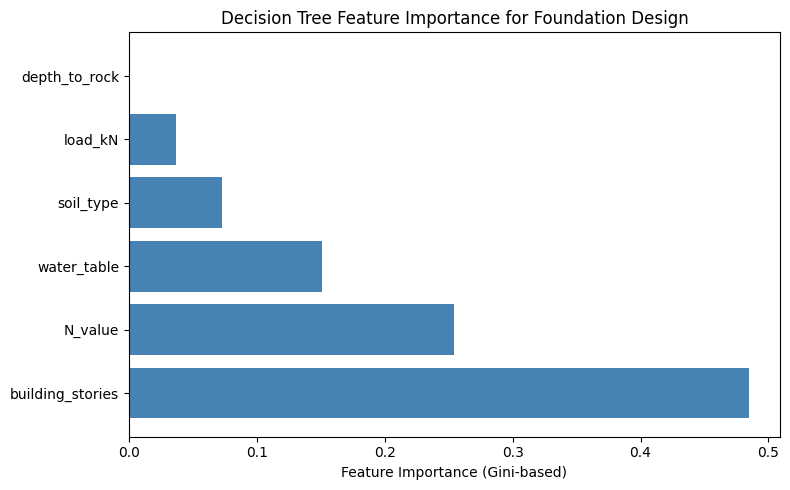

Feature Importance Ranking:
  building_stories    : 0.4848
  N_value             : 0.2545
  water_table         : 0.1509
  soil_type           : 0.0729
  load_kN             : 0.0370
  depth_to_rock       : 0.0000

The tree relies most on features that create the cleanest splits.
This aligns with engineering intuition: building height and soil
strength (N-value) are the primary drivers of foundation choice.


In [12]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE FROM DECISION TREE
# ─────────────────────────────────────────────────────

importances = dt_pruned.feature_importances_
sorted_idx = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([feature_names[i] for i in sorted_idx],
        importances[sorted_idx], color='steelblue')
ax.set_xlabel('Feature Importance (Gini-based)')
ax.set_title('Decision Tree Feature Importance for Foundation Design')
plt.tight_layout()
plt.show()

print("Feature Importance Ranking:")
print("=" * 45)
for i in sorted_idx:
    print(f"  {feature_names[i]:<20s}: {importances[i]:.4f}")

print(f"\nThe tree relies most on features that create the cleanest splits.")
print(f"This aligns with engineering intuition: building height and soil")
print(f"strength (N-value) are the primary drivers of foundation choice.")

---

## Part 8: Evaluation — Confusion Matrix and Report

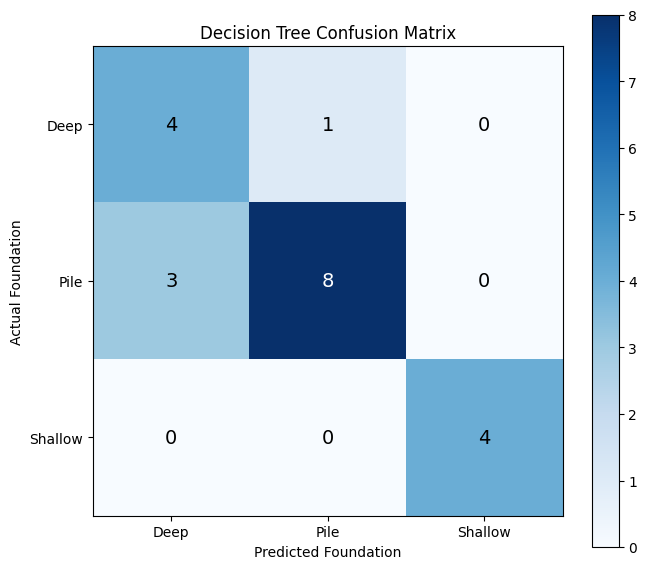

Classification Report:
              precision    recall  f1-score   support

        Deep       0.57      0.80      0.67         5
        Pile       0.89      0.73      0.80        11
     Shallow       1.00      1.00      1.00         4

    accuracy                           0.80        20
   macro avg       0.82      0.84      0.82        20
weighted avg       0.83      0.80      0.81        20



In [13]:
# ─────────────────────────────────────────────────────
# CONFUSION MATRIX
# ─────────────────────────────────────────────────────

y_pred = dt_pruned.predict(X_test)
labels = ['Deep', 'Pile', 'Shallow']
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im, ax=ax)

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.set_xlabel('Predicted Foundation')
ax.set_ylabel('Actual Foundation')
ax.set_title('Decision Tree Confusion Matrix')

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)

plt.tight_layout()
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred))

---

## Part 9: Predict New Projects

In [14]:
# ─────────────────────────────────────────────────────
# PREDICT FOUNDATION FOR NEW PROJECTS
# ─────────────────────────────────────────────────────

new_projects = pd.DataFrame({
    'soil_type_encoded': le_soil.transform(['Sand', 'Clay', 'Gravel', 'Silt']),
    'N_value': [35, 5, 40, 12],
    'building_stories': [2, 15, 3, 8],
    'load_kN': [600, 4500, 900, 2400],
    'water_table': [8.0, 1.5, 10.0, 3.0],
    'depth_to_rock': [3.0, 20.0, 2.0, 12.0]
})

preds = dt_pruned.predict(new_projects)

print("Foundation Recommendations for New Projects")
print("=" * 70)
soils = ['Sand', 'Clay', 'Gravel', 'Silt']
for i in range(len(new_projects)):
    row = new_projects.iloc[i]
    print(f"  Project {i+1}: {soils[i]:6s} soil, N={row['N_value']:2.0f}, "
          f"{row['building_stories']:.0f}-story, {row['load_kN']:.0f} kN")
    print(f"            Water table={row['water_table']:.1f}m, Rock at {row['depth_to_rock']:.1f}m")
    print(f"            Recommendation: {preds[i]}")
    print()

Foundation Recommendations for New Projects
  Project 1: Sand   soil, N=35, 2-story, 600 kN
            Water table=8.0m, Rock at 3.0m
            Recommendation: Shallow

  Project 2: Clay   soil, N= 5, 15-story, 4500 kN
            Water table=1.5m, Rock at 20.0m
            Recommendation: Pile

  Project 3: Gravel soil, N=40, 3-story, 900 kN
            Water table=10.0m, Rock at 2.0m
            Recommendation: Shallow

  Project 4: Silt   soil, N=12, 8-story, 2400 kN
            Water table=3.0m, Rock at 12.0m
            Recommendation: Pile



---

## Practice Exercises

### Exercise 1: Minimum Samples per Leaf
Train a tree with `min_samples_leaf=5`. How does it compare to the pruned tree in accuracy and number of leaves?

### Exercise 2: Entropy Criterion
Visualize the tree trained with `criterion='entropy'`. Are the splits different from the Gini-based tree?

### Exercise 3: Engineering Interpretation
Look at the pruned tree visualization. Write down the top 3 rules the tree learned. Do they match standard engineering practice?

In [15]:
# EXERCISE 1: min_samples_leaf
# dt_leaf = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
# dt_leaf.fit(X_train, y_train)
# print(f"Leaves: {dt_leaf.get_n_leaves()}, Accuracy: {dt_leaf.score(X_test, y_test):.2%}")

In [16]:
# EXERCISE 2: Entropy tree visualization
# dt_ent = DecisionTreeClassifier(criterion='entropy', max_depth=best_depth, random_state=42)
# dt_ent.fit(X_train, y_train)
# fig, ax = plt.subplots(figsize=(16, 8))
# plot_tree(dt_ent, feature_names=feature_names, class_names=dt_ent.classes_, filled=True, ax=ax)
# plt.show()

---

## Key Takeaways

1. **Decision trees learn if/else rules** from data, making them the most interpretable ML model. Engineers can read the tree and verify the logic matches domain knowledge.

2. **Gini impurity** measures how mixed a node is (0 = pure, higher = more mixed). The tree greedily picks splits that maximize purity gain.

3. **max_depth controls overfitting**: Deep trees memorize training data (100% training accuracy but poor generalization). Shallower trees capture the main patterns without noise.

4. **Feature importance** reveals which inputs drive decisions most. For foundation design, building height and soil strength dominate — matching engineering intuition.

5. **Single trees are unstable** — small data changes can produce very different trees. Tomorrow we fix this with Random Forests (ensembles of many trees).

---

## How This Connects to ML

| What We Did Today | ML Equivalent |
|-------------------|---------------|
| Foundation type classification | Multi-class classification |
| Gini impurity calculation | Splitting criterion optimization |
| max_depth tuning | Regularization / complexity control |
| plot_tree visualization | Model interpretability / explainability |
| Feature importance ranking | Feature selection guidance |
| export_text rules | Rule extraction for deployment |
| Gini vs Entropy comparison | Hyperparameter selection |

---

*Day 041 of 100 — Decision trees: the only ML model you can print and hang on the wall!*